# 01 · Auditoría de datos (Fase 3)
Se revisan las fuentes **sin modificarlas** y se decide si permiten responder la pregunta.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import display, Markdown
pd.set_option("display.max_columns", 30)
from src.config import *

In [2]:
from src.data import emovi
raw = emovi.load_raw()
print("Observaciones y variables:", raw.shape)
print("Folios duplicados:", raw["index"].duplicated().sum())
print("Edad:", raw.edad.min(), "-", raw.edad.max())
print("Población representada (suma de factores):", f"{raw.factor.sum():,.0f}")

Observaciones y variables: (17843, 296)
Folios duplicados: 0
Edad: 25 - 64
Población representada (suma de factores): 60,005,360


In [3]:
rep = emovi.missing_report(raw)
rep.to_csv(TABLES / "auditoria_faltantes.csv")
clave = ["educp", "educm", "clasep", "clase", "educ", "p22", "p57", "p58", "p113dL", "ingc_pc", "factor"]
display(rep.loc[clave])

,faltante_pct,codigo_ns_pct
educp,18.89,0.00
educm,10.34,0.00
clasep,15.63,0.00
clase,33.16,0.00
educ,1.64,0.00
p22,0.00,7.18
p57,1.99,4.35
p58,7.14,1.40
p113dL,4.21,0.00
ingc_pc,0.00,0.00


**Lectura:** los activos del hogar a los 14 años tienen menos de 5% de "No sabe". La escolaridad del padre falta en 19% de los casos y la de la madre en 10%. Esos faltantes **no son aleatorios**: suelen ser un padre o una madre ausente. Por eso se conservan como una categoría propia ("No sabe / ausente") y no se imputan.

`clase` (la ocupación actual) falta en 33%, porque solo aplica a quien trabaja. No se usa como predictor.

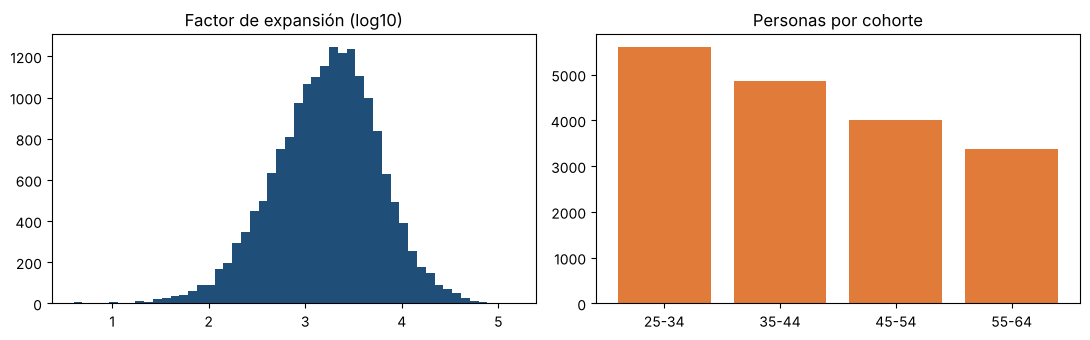

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(np.log10(raw.factor), bins=50, color="#1f4e79"); ax[0].set_title("Factor de expansión (log10)")
ax[1].bar(["25-34","35-44","45-54","55-64"], raw.cohorte.value_counts().sort_index(), color="#e07b39"); ax[1].set_title("Personas por cohorte")
plt.tight_layout(); plt.show()

## Fuentes complementarias
| Fuente | Archivo | Unidad | Uso |
|---|---|---|---|
| CONEVAL 2022 | `pobreza_22.dta` | Persona (construida con la ENIGH 2022) | % de pobreza y pobreza extrema por estado |
| ENOE 2022 (4 trimestres) | `ENOEN_SDEMT*22.dta` | Persona ocupada | Tasa de informalidad laboral por estado |
| ENIGH 2022 | 7 tablas | Hogar y persona | Ya está incluida en la medición de CONEVAL, así que no se procesa por separado |

Estas fuentes **no se unen persona por persona** con la EMOVI. Solo se resumen por estado.

In [5]:
from src.data import context
ctx, nac = context.build()
ctx.to_csv(PROCESSED / "contexto_estatal_2022.csv")
print(f"Validación contra cifras oficiales 2022 — pobreza nacional: {nac['pobreza_pct']:.1f}% (CONEVAL publica 36.3%), extrema: {nac['pobreza_extrema_pct']:.1f}% (publica 7.1%)")
display(ctx.sort_values("pobreza_pct", ascending=False).head(8))

   ENOEN_SDEMT222.dta listo


   ENOEN_SDEMT122.dta listo


   ENOEN_SDEMT422.dta listo


   ENOEN_SDEMT322.dta listo
Validación contra cifras oficiales 2022 — pobreza nacional: 36.3% (CONEVAL publica 36.3%), extrema: 7.1% (publica 7.1%)


,entidad,pobreza_pct,pobreza_extrema_pct,ingreso_pc_mensual,informalidad_pct
entidad_cve,,,,,
7,Chiapas,67.37,28.21,3403.82,75.72
12,Guerrero,60.35,22.23,4022.55,79.02
20,Oaxaca,58.44,20.23,4064.48,81.20
21,Puebla,54.02,11.40,4380.32,71.16
29,Tlaxcala,52.52,6.75,4060.38,71.57
30,Veracruz,51.73,13.14,4522.53,67.65
27,Tabasco,46.47,11.16,4880.38,63.70
4,Campeche,45.13,9.64,5352.13,61.81


## Puerta de decisión de datos: 🟢 **VERDE**
- La EMOVI tiene **origen** (hogar a los 14 años, padres) y **destino** (hogar actual) para las mismas 17,843 personas, con factor de expansión y diseño muestral.
- Sí permite medir movilidad intergeneracional relativa. Ruta del roadmap: **clasificación** (seguir en Q1 o no) más análisis descriptivo de transiciones.
- Restricciones: el origen es **retrospectivo** (depende de la memoria), no hay ingreso de los padres y el diseño es transversal (sin causalidad).

**Estado de la fase:** PROPUESTA — falta la revisión humana (regla de avance del roadmap: APROBADA / APROBADA CON CAMBIOS / REABRIR / BLOQUEADA).